## 01 · MinMaxScaler 정규화
교재 **119–120쪽**

In [1]:
# 데이터 핸들링을 위한 pandas와 Scikit-learn의 MinMaxScaler를 불러옵니다.
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

# 실습을 위해 데이터를 다시 불러옵니다.
df = pd.read_csv("Part3 House Price.csv")

# 이전 챕터에서 컬럼명을 GrLivArea -> LivingArea로 변경했다고 가정합니다.
# 만약 실행이 안된다면 아래 주석을 해제하세요.
# df.rename(columns={‘GrLivArea’: ‘LivingArea’}, inplace=True)
df.rename(columns={'GrLivArea': 'LivingArea'}, inplace=True)

# MinMaxScaler 객체를 생성합니다.
scaler = MinMaxScaler()

# 원본 ‘LivingArea’ 컬럼의 상위 5개 값을 확인합니다.
print("--- 정규화 전 데이터 ---")
print(df['LivingArea'].head())

# MinMaxScaler를 사용해 ‘LivingArea’ 컬럼을 정규화합니다.
# fit_transform은 2D 배열을 입력으로 기대하므로, 대괄호를 두 번 사용해 [[...]] 형태로 만들어 줍니다.
df['LivingArea_MMS'] = scaler.fit_transform(df[['LivingArea']])

# 정규화 후 생성된 새로운 컬럼의 상위 5개 값을 확인합니다.
print("\n--- 정규화 후 데이터 ---")
print(df['LivingArea_MMS'].head())

--- 정규화 전 데이터 ---
0    1710
1    1262
2    1786
3    1717
4    2198
Name: LivingArea, dtype: int64

--- 정규화 후 데이터 ---
0    0.259231
1    0.174830
2    0.273549
3    0.260550
4    0.351168
Name: LivingArea_MMS, dtype: float64


## 02 · 정규화 전후 분포 비교
교재 **121쪽**

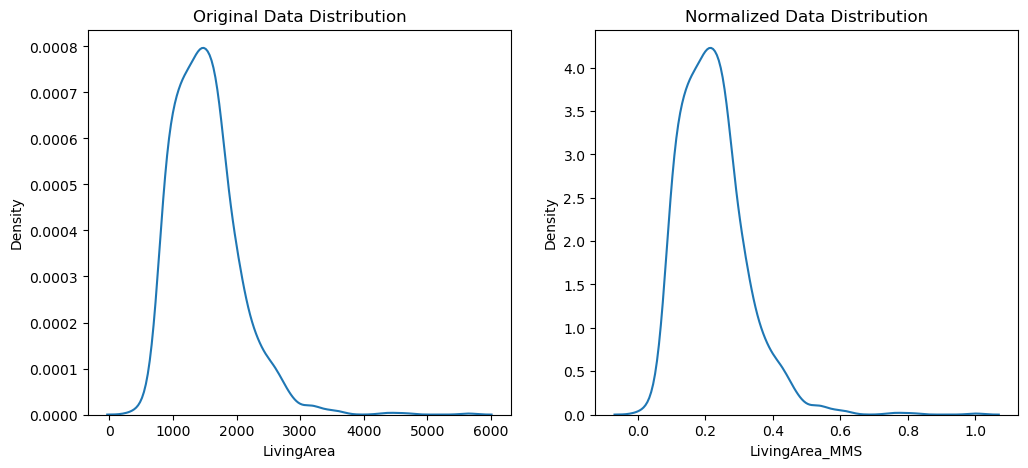

In [2]:
# 데이터 시각화를 위한 라이브러리를 불러옵니다.
import seaborn as sns
import matplotlib.pyplot as plt

# 1행 2열의 그래프를 그릴 공간(fig)과 각 그래프가 그려질 축(axes)을 만듭니다.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 첫 번째 그래프(axes[0])에 원본 데이터의 분포를 그립니다.
sns.kdeplot(df['LivingArea'], ax=axes[0])
axes[0].set_title('Original Data Distribution')

# 두 번째 그래프(axes[1])에 정규화된 데이터의 분포를 그립니다.
sns.kdeplot(df['LivingArea_MMS'], ax=axes[1])
axes[1].set_title('Normalized Data Distribution')

# 그래프를 화면에 보여줍니다.
plt.show()

## 03 · StandardScaler 표준화
교재 **122쪽**

In [3]:
# 데이터 핸들링을 위한 pandas와 Scikit-learn의 StandardScaler를 불러옵니다.
import pandas as pd
from sklearn.preprocessing import StandardScaler

# 실습을 위해 데이터를 다시 불러옵니다.
df = pd.read_csv("Part3 House Price.csv")

# 이전 챕터에서 컬럼명을 GrLivArea -> LivingArea로 변경했다고 가정합니다.
# 만약 실행이 안된다면 아래 주석을 해제하세요.
# df.rename(columns={‘GrLivArea’: ‘LivingArea’}, inplace=True)
df.rename(columns={'GrLivArea': 'LivingArea'}, inplace=True)

# StandardScaler 객체를 생성합니다.
scaler = StandardScaler()

# 원본 ‘LivingArea’ 컬럼의 상위 5개 값을 확인합니다.
print("--- 표준화 전 데이터 ---")
print(df['LivingArea'].head())

# StandardScaler를 사용해 ‘LivingArea’ 컬럼을 표준화합니다.
# fit_transform()은 2D 배열을 입력으로 기대하므로, 대괄호를 두 번 사용해 [[...]] 형태로 만들어줍니다.
df['LivingArea_SS'] = scaler.fit_transform(df[['LivingArea']])

# 표준화 후 생성된 새로운 컬럼의 상위 5개 값을 확인합니다.
print("\n--- 표준화 후 데이터 ---")
print(df['LivingArea_SS'].head())

--- 표준화 전 데이터 ---
0    1710
1    1262
2    1786
3    1717
4    2198
Name: LivingArea, dtype: int64

--- 표준화 후 데이터 ---
0    0.370333
1   -0.482512
2    0.515013
3    0.383659
4    1.299326
Name: LivingArea_SS, dtype: float64


## 04 · RobustScaler 중앙값과 IQR
교재 **123–124쪽**

In [4]:
import pandas as pd
from sklearn.preprocessing import RobustScaler

# 데이터를 불러옵니다.
df = pd.read_csv("Part3 House Price.csv")

# 이전 챕터에서 컬럼명을 GrLivArea → LivingArea로 변경했다고 가정합니다.
# 만약 실행이 안된다면 아래 주석을 해제하세요.
# df.rename(columns={'GrLivArea': 'LivingArea'}, inplace=True)
# RobustScaler 객체를 생성합니다.
scaler = RobustScaler()
print("--- 스케일링 전 데이터 ---")
print(df[['GrLivArea']].head())

# RobustScaler를 사용해 ‘GrLivArea’ 컬럼을 스케일링합니다.
df['GrLivArea_RS'] = scaler.fit_transform(df[['GrLivArea']])

# 스케일링 후 생성된 새로운 컬럼의 상위 5개 값을 확인합니다.
print("\n--- 스케일링 후 데이터 ---")
print(df[['GrLivArea', 'GrLivArea_RS']].head())

--- 스케일링 전 데이터 ---
   GrLivArea
0       1710
1       1262
2       1786
3       1717
4       2198

--- 스케일링 후 데이터 ---
   GrLivArea  GrLivArea_RS
0       1710      0.380070
1       1262     -0.312090
2       1786      0.497489
3       1717      0.390885
4       2198      1.134029


## 05 · 네 가지 분포 한눈에 비교
교재 **125–126쪽**

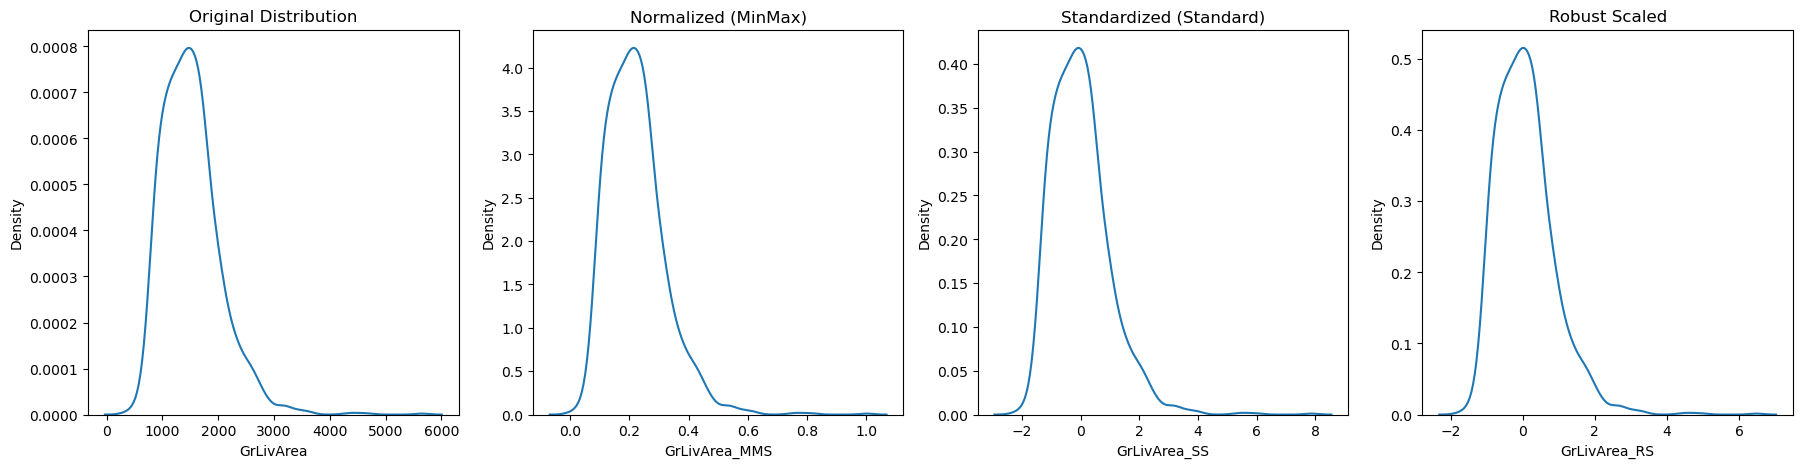

In [5]:
# 데이터 시각화를 위한 라이브러리를 불러옵니다.
import seaborn as sns
import matplotlib.pyplot as plt

# 스케일러들을 모두 불러옵니다.
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

# 데이터를 불러옵니다.
df = pd.read_csv("Part3 House Price.csv")

# 정규화 컬럼(LivingArea_MMS)과 표준화 컬럼(LivingArea_SS)을 다시 생성합니다.
# 이 부분은 이전 코드에서 이미 실행했다면 생략해도 좋습니다.
norm_scaler = MinMaxScaler()
std_scaler = StandardScaler()
robust_scaler = RobustScaler()
df['GrLivArea_MMS'] = norm_scaler.fit_transform(df[['GrLivArea']])
df['GrLivArea_SS']  = std_scaler.fit_transform(df[['GrLivArea']])
df['GrLivArea_RS']  = robust_scaler.fit_transform(df[['GrLivArea']])

# --- 시각화 ---
# 1행 4열의 그래프를 그릴 공간(fig)과 각 그래프가 그려질 축(axes)을 만듭니다.
fig, axes = plt.subplots(1, 4, figsize=(22, 5))

# 첫 번째 그래프(axes[0])에 원본 데이터의 분포를 그립니다.
sns.kdeplot(df['GrLivArea'], ax=axes[0])
axes[0].set_title('Original Distribution')

# 두 번째 그래프(axes[1])에 정규화된 데이터의 분포를 그립니다.
sns.kdeplot(df['GrLivArea_MMS'], ax=axes[1])
axes[1].set_title('Normalized (MinMax)')

# 세 번째 그래프(axes[2])에 표준화된 데이터의 분포를 그립니다.
sns.kdeplot(df['GrLivArea_SS'], ax=axes[2])
axes[2].set_title('Standardized (Standard)')

# 네 번째 그래프(axes[3])에 로버스트 스케일링된 데이터의 분포를 그립니다.
sns.kdeplot(df['GrLivArea_RS'], ax=axes[3])
axes[3].set_title('Robust Scaled')

# 그래프를 화면에 보여줍니다.
plt.show()